In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/elikplim/eergy-efficiency-dataset/ENB2012_data.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/elikplim/eergy-efficiency-dataset/ENB2012_data.csv


In [3]:
# Load Dataset

df = pd.read_csv(
    '/kaggle/input/datasets/elikplim/eergy-efficiency-dataset/ENB2012_data.csv'
)

# Display first 5 rows
df.head()

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [4]:
# Dataset Information

print("Dataset Shape:", df.shape)

print("\nDataset Info:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
df.describe()

Dataset Shape: (768, 10)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      768 non-null    float64
 1   X2      768 non-null    float64
 2   X3      768 non-null    float64
 3   X4      768 non-null    float64
 4   X5      768 non-null    float64
 5   X6      768 non-null    int64  
 6   X7      768 non-null    float64
 7   X8      768 non-null    int64  
 8   Y1      768 non-null    float64
 9   Y2      768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB

Missing Values:
X1    0
X2    0
X3    0
X4    0
X5    0
X6    0
X7    0
X8    0
Y1    0
Y2    0
dtype: int64

Statistical Summary:


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
count,768.000000,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000,768.000000,768.000000
mean,0.764167,671.708333,318.500000,176.604167,5.25000,3.500000,0.234375,2.81250,22.307201,24.587760
std,0.105777,88.086116,43.626481,45.165950,1.75114,1.118763,0.133221,1.55096,10.090196,9.513306
min,0.620000,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000,6.010000,10.900000
25%,0.682500,606.375000,294.000000,140.875000,3.50000,2.750000,0.100000,1.75000,12.992500,15.620000
50%,0.750000,673.750000,318.500000,183.750000,5.25000,3.500000,0.250000,3.00000,18.950000,22.080000
75%,0.830000,741.125000,343.000000,220.500000,7.00000,4.250000,0.400000,4.00000,31.667500,33.132500
max,0.980000,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000,43.100000,48.030000


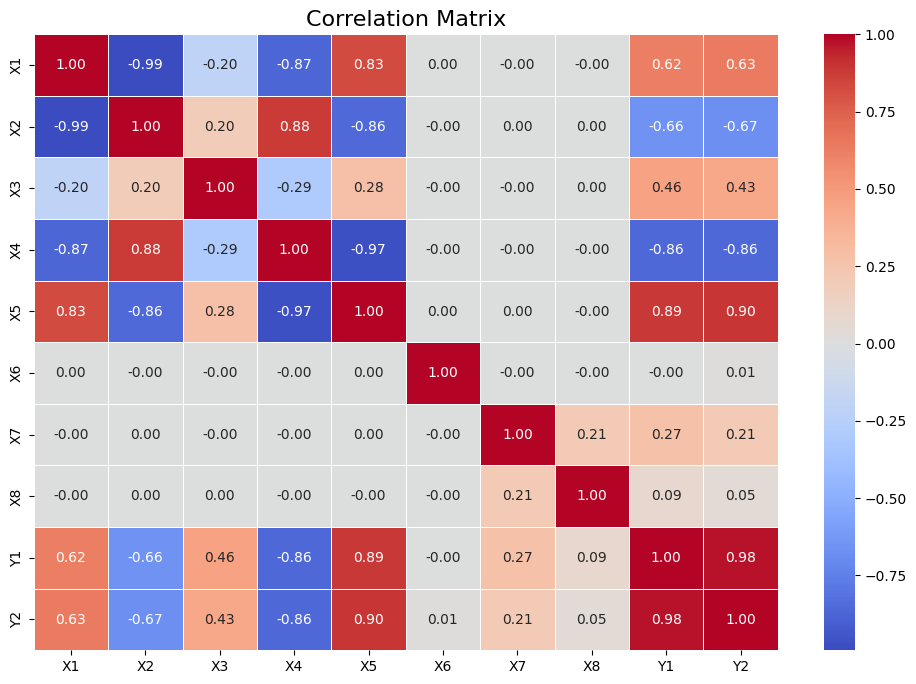

In [5]:
# Correlation Matrix

plt.figure(figsize=(12, 8))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix', fontsize=16)
plt.show()

In [6]:
# Check relationships with Heating Load

for feature in ['X1', 'X2', 'X4', 'X5']:

    print(f"\n{feature} vs Heating Load")

    print("Correlation:",
          df[feature].corr(df['Y1']))

    print("Unique values:",
          df[feature].nunique())

    print("Minimum:",
          df[feature].min())

    print("Maximum:",
          df[feature].max())


X1 vs Heating Load
Correlation: 0.6222721790646633
Unique values: 12
Minimum: 0.62
Maximum: 0.98

X2 vs Heating Load
Correlation: -0.6581202267776216
Unique values: 12
Minimum: 514.5
Maximum: 808.5

X4 vs Heating Load
Correlation: -0.8618282529058238
Unique values: 4
Minimum: 110.25
Maximum: 220.5

X5 vs Heating Load
Correlation: 0.8894306741007039
Unique values: 2
Minimum: 3.5
Maximum: 7.0


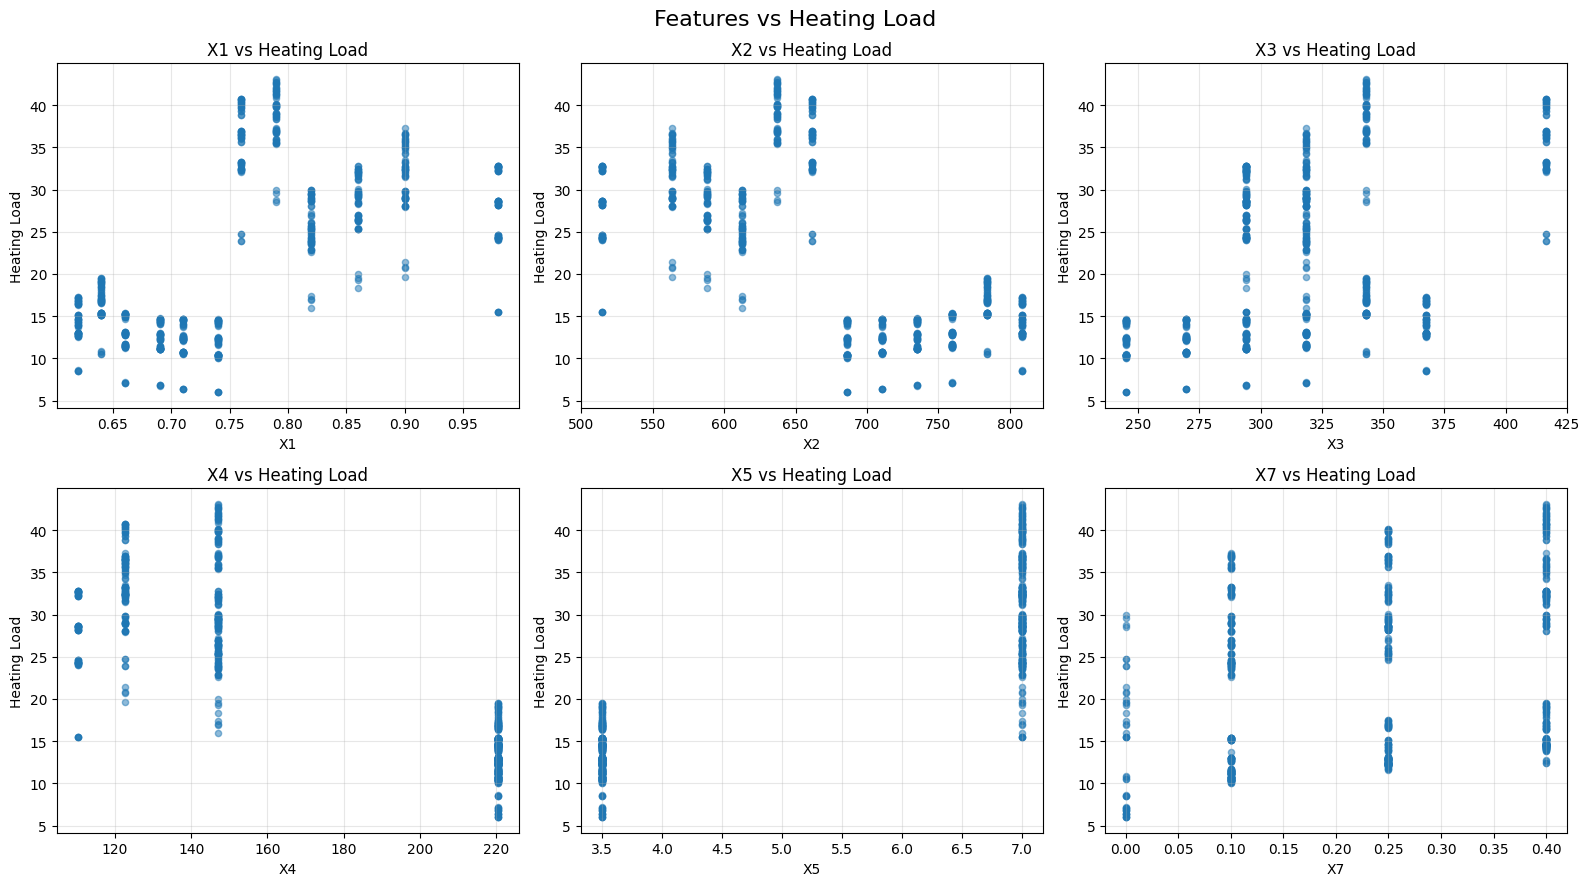

In [7]:
# Features vs Heating Load

features = ['X1', 'X2', 'X3', 'X4', 'X5', 'X7']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, feature in zip(axes.flatten(), features):

    ax.scatter(df[feature], df['Y1'],
               alpha=0.5, s=20)

    ax.set_xlabel(feature)
    ax.set_ylabel('Heating Load')
    ax.set_title(f'{feature} vs Heating Load')
    ax.grid(alpha=0.3)

plt.suptitle('Features vs Heating Load', fontsize=16)
plt.tight_layout()
plt.show()

In [8]:
# Analyze Categorical Features

print("X6 Categories:")
print(df['X6'].value_counts().sort_index())

print("\nX8 Categories:")
print(df['X8'].value_counts().sort_index())

print("\nHeating Load by X5:")
print(df.groupby('X5')['Y1'].mean())

print("\nHeating Load by X6:")
print(df.groupby('X6')['Y1'].mean())

print("\nHeating Load by X8:")
print(df.groupby('X8')['Y1'].mean())

X6 Categories:
X6
2    192
3    192
4    192
5    192
Name: count, dtype: int64

X8 Categories:
X8
0     48
1    144
2    144
3    144
4    144
5    144
Name: count, dtype: int64

Heating Load by X5:
X5
3.5    13.338516
7.0    31.275885
Name: Y1, dtype: float64

Heating Load by X6:
X6
2    22.312865
3    22.380677
4    22.259896
5    22.275365
Name: Y1, dtype: float64

Heating Load by X8:
X8
0    14.286458
1    23.026111
2    22.934444
3    22.681458
4    22.886667
5    22.680903
Name: Y1, dtype: float64


In [9]:
# Features and Target

X = df.drop(columns=['Y1', 'Y2'])
y = df['Y1']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Features Shape: (768, 8)
Target Shape: (768,)

Features:
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8']


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify categorical and numerical features
categorical_features = ['X6', 'X8']
numerical_features = ['X1', 'X2', 'X3', 'X4', 'X5', 'X7']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Fit on training data only
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

Training Data Shape: (614, 16)
Testing Data Shape: (154, 16)


In [11]:
from sklearn.preprocessing import PolynomialFeatures

# Apply Polynomial Features
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train_processed)
X_test_poly = poly.transform(X_test_processed)

print("Polynomial Training Shape:", X_train_poly.shape)
print("Polynomial Testing Shape:", X_test_poly.shape)

Polynomial Training Shape: (614, 152)
Polynomial Testing Shape: (154, 152)


In [12]:
# Scale Target
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

y_test_scaled = y_scaler.transform(
    y_test.to_numpy().reshape(-1, 1)
).ravel()

print("Scaled Training Target:", y_train_scaled.shape)
print("Scaled Testing Target:", y_test_scaled.shape)

Scaled Training Target: (614,)
Scaled Testing Target: (154,)


In [13]:
# Initialize Parameters

n_samples, n_features = X_train_poly.shape

weights = np.zeros(n_features)
bias = 0.0

# Hyperparameters
learning_rate = 0.01
epochs = 1000
momentum = 0.9

# Momentum variables
velocity_w = np.zeros(n_features)
velocity_b = 0.0

loss_history = []

# Gradient Descent with Momentum
for epoch in range(epochs):

    # Forward Pass
    y_pred = np.dot(X_train_poly, weights) + bias

    # Calculate Error
    error = y_pred - y_train_scaled

    # Calculate Gradients
    dw = (2 / n_samples) * np.dot(X_train_poly.T, error)
    db = (2 / n_samples) * np.sum(error)

    # Update Momentum
    velocity_w = momentum * velocity_w + learning_rate * dw
    velocity_b = momentum * velocity_b + learning_rate * db

    # Update Parameters
    weights -= velocity_w
    bias -= velocity_b

    # Calculate Loss
    loss = np.mean(error ** 2)
    loss_history.append(loss)

print("Final Training Loss:", loss_history[-1])

Final Training Loss: 0.04569891965115979


In [14]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [15]:
# Predictions on Test Data
y_pred_scaled = np.dot(X_test_poly, weights) + bias

# Convert predictions back to original scale
y_pred = y_scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

y_test_original = y_test.to_numpy()

# Evaluation Metrics
mse = mean_squared_error(y_test_original, y_pred)
mae = mean_absolute_error(y_test_original, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_original, y_pred)

print("GD with Momentum Results")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

GD with Momentum Results
------------------------
MAE: 1.683537054675432
MSE: 5.6203627078949765
RMSE: 2.3707304165372696
R2 Score: 0.9460781047477261


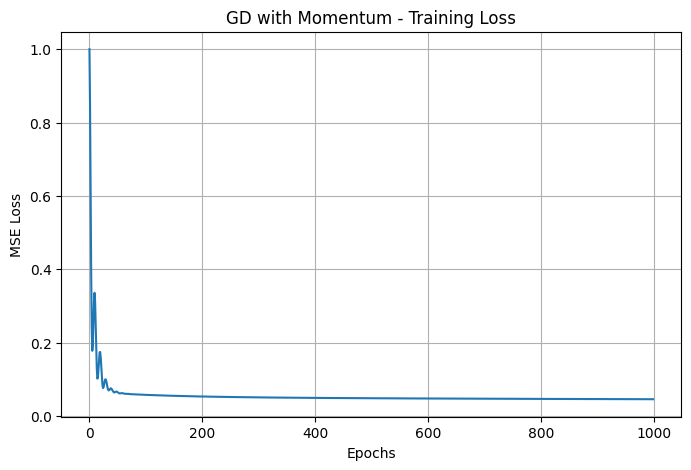

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.title('GD with Momentum - Training Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.grid(True)
plt.show()

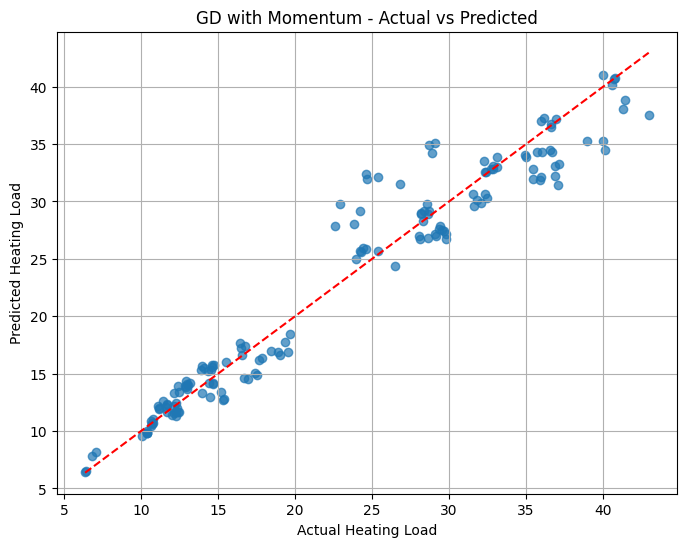

In [17]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test_original, y_pred, alpha=0.7)

plt.plot(
    [y_test_original.min(), y_test_original.max()],
    [y_test_original.min(), y_test_original.max()],
    'r--'
)

plt.title('GD with Momentum - Actual vs Predicted')
plt.xlabel('Actual Heating Load')
plt.ylabel('Predicted Heating Load')
plt.grid(True)
plt.show()

In [18]:
# Save GD Results

gd_results = pd.DataFrame({
    'Optimizer': ['GD with Momentum'],
    'MAE': [mae],
    'MSE': [mse],
    'RMSE': [rmse],
    'R2 Score': [r2]
})

gd_results.to_csv('GD_Results.csv', index=False)

print("GD Results saved successfully!")
gd_results

GD Results saved successfully!


,Optimizer,MAE,MSE,RMSE,R2 Score
0,GD with Momentum,1.683537,5.620363,2.37073,0.946078
